# Video 11: Cell to cell spatial interaction

Notes for this notebook.

This notebook generates the visuals for the eleventh video in the Multimodal Spatial Biology series. In Video 8, we asked whether each cell population clusters with itself. Here we ask a more specific question, do particular pairs of cell types sit next to each other more, or less, than random chance would predict. This tells us about tissue organization and cell to cell relationships, not just whether a population is spatially grouped.

This notebook reuses the cluster assignments from Video 7. All output images are saved into outputs/video11.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


In [2]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/video11")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


Output folder ready at: C:\Users\m6sbhatt\Documents\Personal\python_projects\unumlocalia\outputs\video11


## Load clusters and assign working names

We reuse the five Leiden clusters from Video 7. To make the results easier to read, we assign a working name to each cluster based on the marker profile we found in that video.


In [3]:
df = pd.read_csv("outputs/video7/core01_hcc_clusters.csv")

cluster_names = {
    0: "Epithelial A",
    1: "Immune",
    2: "Stromal",
    3: "Epithelial B",
    4: "Lymphatic-like",
}
df["cell_type"] = df["leiden_cluster"].map(cluster_names)

print(df["cell_type"].value_counts())


cell_type
Epithelial A      2062
Immune            2043
Stromal           1791
Epithelial B      1544
Lymphatic-like     843
Name: count, dtype: int64


## Measuring every pairwise relationship

For each cell, we look at its ten nearest neighbors, the same approach as Video 8, but this time we build a full matrix, for every cell type, what fraction of its neighbors belong to each of the five types, including itself.


In [4]:
from sklearn.neighbors import NearestNeighbors

coords = df[["centroid_x", "centroid_y"]].values
labels = df["cell_type"].values
unique_types = sorted(df["cell_type"].unique())

k = 10
nbrs = NearestNeighbors(n_neighbors=k + 1).fit(coords)
_, neighbor_idx = nbrs.kneighbors(coords)
neighbor_idx = neighbor_idx[:, 1:]


def pairwise_fraction_matrix(labels, neighbor_idx, unique_types):
    neighbor_labels = labels[neighbor_idx]
    matrix = pd.DataFrame(0.0, index=unique_types, columns=unique_types)
    for t in unique_types:
        mask = labels == t
        for other_t in unique_types:
            frac = (neighbor_labels[mask] == other_t).mean()
            matrix.loc[t, other_t] = frac
    return matrix


observed_matrix = pairwise_fraction_matrix(labels, neighbor_idx, unique_types)
print("Observed neighbor type fractions, rows are a cell's own type, columns are its neighbors' type:")
print(observed_matrix.round(3))


Observed neighbor type fractions, rows are a cell's own type, columns are its neighbors' type:
                Epithelial A  Epithelial B  Immune  Lymphatic-like  Stromal
Epithelial A           0.465         0.270   0.038           0.170    0.057
Epithelial B           0.367         0.449   0.041           0.092    0.051
Immune                 0.041         0.032   0.597           0.018    0.313
Lymphatic-like         0.404         0.154   0.039           0.340    0.064
Stromal                0.071         0.046   0.373           0.033    0.478


As with Video 8, a raw fraction alone does not tell us whether a relationship is meaningful, common cell types will naturally show up as neighbors more often just by being common. We shuffle cell type labels across the same positions, many times, to see what these fractions would look like under no real spatial relationship at all, then compare our real result against that.


In [5]:
n_permutations = 100
rng = np.random.default_rng(0)
null_matrices = []

for i in range(n_permutations):
    shuffled = rng.permutation(labels)
    null_matrices.append(pairwise_fraction_matrix(shuffled, neighbor_idx, unique_types).values)

null_stack = np.array(null_matrices)
null_mean = null_stack.mean(axis=0)
null_std = null_stack.std(axis=0)

z_matrix = pd.DataFrame(
    (observed_matrix.values - null_mean) / null_std,
    index=unique_types, columns=unique_types
)
print("Z-score matrix, positive means enriched adjacency, negative means avoidance:")
print(z_matrix.round(2))


Z-score matrix, positive means enriched adjacency, negative means avoidance:
                Epithelial A  Epithelial B  Immune  Lymphatic-like  Stromal
Epithelial A           57.81         35.28  -69.79           34.29   -62.84
Epithelial B           39.65         68.37  -71.94           -3.59   -51.76
Immune                -68.36        -67.07  101.48          -42.99    38.26
Lymphatic-like         32.06         -6.53  -45.41           50.37   -37.59
Stromal               -61.48        -53.61   43.45          -36.96    67.91


## Reading the matrix

The diagonal confirms what Video 8 already showed, every population sits near itself far more than chance predicts. The interesting part is off the diagonal.

Immune and Stromal cells show strong, mutual, positive enrichment with each other, and both show strong, mutual avoidance of both epithelial populations. This is a direct, quantitative demonstration of immune exclusion, immune cells are not simply failing to reach the tumor cells at random, they are specifically concentrated in and around stromal tissue instead, consistent with the immune aggregate sitting near the branching stromal septa that we first noticed back in the registration video, and consistent with the broader immune presence difference we measured between tumor and non tumor tissue in Video 5.

The two epithelial populations show mild positive enrichment with each other, weaker than their own self enrichment, suggesting some mixing at nodule boundaries while largely occupying separate territory, plausible evidence of real heterogeneity between tumor regions rather than one uniform population.

The lymphatic-like population, the smallest and newest population from Video 7, shows its own distinct neighborhood, enriched next to Epithelial A specifically, and strongly avoiding both Immune and Stromal. This is a genuinely separate spatial niche from every other population in the tissue, further evidence that this small cluster reflects a real, distinct structure.


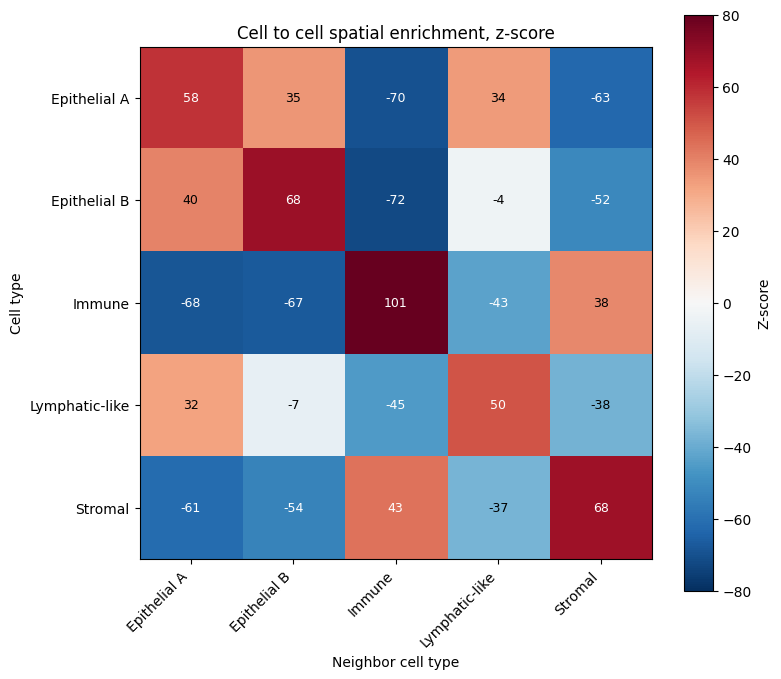

Saved slide_cell_interaction_matrix.png


In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(z_matrix.values, cmap="RdBu_r", vmin=-80, vmax=80)
ax.set_xticks(range(len(unique_types)))
ax.set_yticks(range(len(unique_types)))
ax.set_xticklabels(unique_types, rotation=45, ha="right")
ax.set_yticklabels(unique_types)
ax.set_xlabel("Neighbor cell type")
ax.set_ylabel("Cell type")
ax.set_title("Cell to cell spatial enrichment, z-score")

for i in range(len(unique_types)):
    for j in range(len(unique_types)):
        ax.text(j, i, f"{z_matrix.values[i, j]:.0f}", ha="center", va="center",
                color="white" if abs(z_matrix.values[i, j]) > 40 else "black", fontsize=9)

plt.colorbar(im, ax=ax, label="Z-score")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_cell_interaction_matrix.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_cell_interaction_matrix.png")


## Summary

Moving from single cell type clustering to pairwise relationships revealed real tissue organization, not just where each population sits, but how populations relate to each other. Immune and stromal cells travel together and both avoid the tumor parenchyma, a formal, quantitative version of immune exclusion. The two epithelial populations occupy mostly separate territory. The lymphatic-like population has its own distinct neighborhood entirely.

Next episode, we look at this from a different angle, whether the morphological features we already measured during segmentation, cell size and shape, actually predict which molecular cluster a cell belongs to, connecting the imaging side of this series back to the molecular side.
